In [2]:
# Sources: Lab 3/docs/implementation.md; Lab 3/docs/sources.md
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset, DatasetDict
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, ConfusionMatrixDisplay
from transformers import (pipeline, AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer, EarlyStoppingCallback, set_seed)

ROOT = Path('Lab 3') if Path('Lab 3').is_dir() else Path('.')
MODEL_NAME = 'distilbert/distilbert-base-uncased'
set_seed(42)
print('Thiết bị:', 'CUDA' if torch.cuda.is_available() else 'CPU')


c:\Users\Legion\Desktop\TÀI LIỆU HỌC\Lab\Lab 3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thiết bị: CUDA


In [3]:
# Sources: Lab 3/docs/model.md; Lab 3/docs/demo.md
classifier = pipeline('text-classification', model='tabularisai/multilingual-sentiment-analysis')
text = 'Bộ phim này rất hay!'
print('Tokens:', classifier.tokenizer.tokenize(text))
print(classifier(text, truncation=True, max_length=512))
del classifier


Device set to use cuda:0


Tokens: ['Bộ', 'phim', 'này', 'rất', 'hay', '!']
[{'label': 'Positive', 'score': 0.6520066261291504}]


In [4]:
# Sources: Lab 3/docs/data.md; Lab 3/docs/implementation.md
raw_train, raw_test = load_dataset('stanfordnlp/imdb', split=['train', 'test'])
train_ids, val_ids = train_test_split(np.arange(len(raw_train)), test_size=0.2,
                                     stratify=raw_train['label'], random_state=42)
data = DatasetDict(train=raw_train.select(train_ids),
                   validation=raw_train.select(val_ids), test=raw_test)
print({name: len(split) for name, split in data.items()})


{'train': 20000, 'validation': 5000, 'test': 25000}


In [5]:
# Sources: Lab 3/docs/data.md; Lab 3/docs/model.md
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch['text'], truncation=True, max_length=256)

tokenized = data.map(tokenize, batched=True, remove_columns=['text'])
collator = DataCollatorWithPadding(tokenizer)


Map: 100%|██████████| 5000/5000 [00:01<00:00, 4432.23 examples/s]


In [6]:
# Sources: Lab 3/docs/model.md; Lab 3/docs/training.md; Lab 3/docs/implementation.md
CHECKPOINT = ROOT/'outputs/full/checkpoints/best'
TRAIN = not (CHECKPOINT/'config.json').exists()
OUTPUT = ROOT/'outputs/simple-training'
if TRAIN:
    OUTPUT = OUTPUT/datetime.now().strftime('%Y%m%d-%H%M%S')
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME if TRAIN else str(CHECKPOINT), num_labels=2,
    id2label={0: 'NEGATIVE', 1: 'POSITIVE'}, label2id={'NEGATIVE': 0, 'POSITIVE': 1})
print('Chế độ:', 'Huấn luyện mới' if TRAIN else 'Nạp model đã huấn luyện')


Chế độ: Nạp model đã huấn luyện


In [7]:
# Sources: Lab 3/docs/evaluation.md; Lab 3/docs/sources.md
def compute_metrics(prediction):
    logits, labels = prediction
    predicted = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predicted, average='binary', zero_division=0)
    return {'accuracy': accuracy_score(labels, predicted), 'precision': precision,
            'recall': recall, 'f1_binary': f1,
            'f1_macro': f1_score(labels, predicted, average='macro', zero_division=0)}


In [8]:
# Sources: Lab 3/docs/training.md; Lab 3/docs/implementation.md
args = TrainingArguments(
    output_dir=str(OUTPUT), eval_strategy='epoch', save_strategy='epoch',
    learning_rate=2e-5, per_device_train_batch_size=16, per_device_eval_batch_size=16,
    num_train_epochs=3, weight_decay=0.01, max_grad_norm=1.0, optim='adamw_torch',
    load_best_model_at_end=True, metric_for_best_model='accuracy', greater_is_better=True,
    save_total_limit=2, fp16=torch.cuda.is_available(), report_to='none',
    seed=42, logging_steps=50)
trainer = Trainer(
    model=model, args=args, train_dataset=tokenized['train'], eval_dataset=tokenized['validation'],
    processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2, early_stopping_threshold=0.01)])


In [9]:
# Sources: Lab 3/docs/training.md; Lab 3/docs/implementation.md; Lab 3/docs/AI_Usage.md
if TRAIN:
    (OUTPUT/'SOURCES.md').write_text(
        '# Nguồn và phạm vi\n\nÁp dụng mọi artifact trong run này.\n'
        'Căn cứ (từ Lab 3/): docs/implementation.md §6; docs/training.md; docs/model.md; docs/data.md.\n',
        encoding='utf-8')
    trainer.train()
    CHECKPOINT = OUTPUT/'best'
    trainer.save_model(str(CHECKPOINT))
    tokenizer.save_pretrained(str(CHECKPOINT))
else:
    print('Đã nạp checkpoint full; không thực hiện lượt huấn luyện mới.')


Đã nạp checkpoint full; không thực hiện lượt huấn luyện mới.


{'test_loss': 0.3465386629104614, 'test_model_preparation_time': 0.001, 'test_accuracy': 0.91012, 'test_precision': 0.913727705592769, 'test_recall': 0.90576, 'test_f1_binary': 0.9097264071351091, 'test_f1_macro': 0.9101182913846719, 'test_runtime': 35.9189, 'test_samples_per_second': 696.012, 'test_steps_per_second': 43.515}


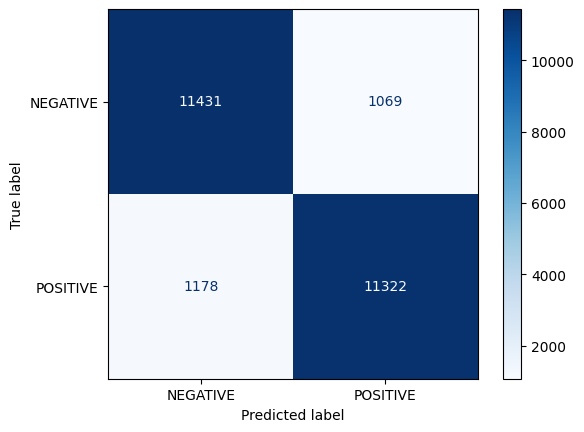

In [10]:
# Sources: Lab 3/docs/evaluation.md
result = trainer.predict(tokenized['test'])
print(result.metrics)
y_pred = result.predictions.argmax(axis=-1)
ConfusionMatrixDisplay.from_predictions(result.label_ids, y_pred, display_labels=['NEGATIVE', 'POSITIVE'], cmap='Blues')
plt.show()


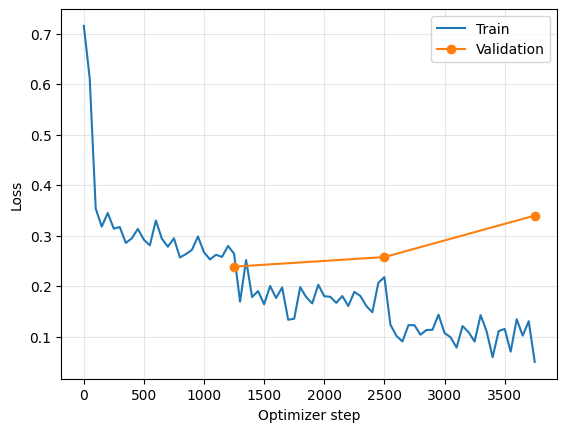

In [11]:
# Sources: Lab 3/docs/evaluation.md; Lab 3/docs/verification.md
if TRAIN:
    history = trainer.state.log_history
else:
    history = json.loads((ROOT/'outputs/full/trainer_history.json').read_text(encoding='utf-8'))['history']
train_log = [row for row in history if 'loss' in row]
val_log = [row for row in history if 'eval_loss' in row]
plt.plot([row['step'] for row in train_log], [row['loss'] for row in train_log], label='Train')
plt.plot([row['step'] for row in val_log], [row['eval_loss'] for row in val_log], 'o-', label='Validation')
plt.xlabel('Optimizer step'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


In [12]:
# Sources: Lab 3/docs/demo.md; Lab 3/docs/model.md
sentiment = pipeline('text-classification', model=str(CHECKPOINT), tokenizer=str(CHECKPOINT),
                     device=0 if torch.cuda.is_available() else -1)
sentences = ['I loved this movie. The acting was great!', 'The movie was boring and disappointing.']
for sentence, prediction in zip(sentences, sentiment(sentences, truncation=True, max_length=256)):
    print(sentence, '->', prediction)


Device set to use cuda:0


I loved this movie. The acting was great! -> {'label': 'POSITIVE', 'score': 0.9967653751373291}
The movie was boring and disappointing. -> {'label': 'NEGATIVE', 'score': 0.9973766803741455}
